# Análise Estatística do Teste de Turing — CV Maxing

Este notebook analisa o estudo **Human vs. AI Tailoring** nos casos Tomás (junior), Pedro (transição de carreira) e Rita (sênior).

Objetivos:
- descodificar A/B/C segundo o contrabalanço do protocolo;
- comparar perceção humana/AI;
- medir escolhas de detecção humana e recomendação para entrevista;
- testar, de forma piloto, as hipóteses H1–H3;
- apresentar limitações e próximos passos.

> Nota: existem 11 respostas válidas. Os resultados são piloto e não representam a população de recrutadores.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest, spearmanr, pointbiserialr
import warnings

warnings.filterwarnings(
    "ignore",
    message="A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy.*",
    category=UserWarning,
)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")

BASE = Path.cwd()
if not (BASE / "turing").exists() and BASE.name != "turing":
    raise FileNotFoundError("Execute o notebook a partir da raiz do projeto ou da pasta turing.")
if BASE.name == "turing":
    BASE = BASE.parent

DATA_DIR = BASE / "turing" / "data"
csv_files = sorted(DATA_DIR.glob("*.csv"), key=lambda path: path.stat().st_mtime, reverse=True)
if not csv_files:
    raise FileNotFoundError(f"Nenhum ficheiro CSV encontrado em {DATA_DIR}")
CSV_PATH = csv_files[0]
RAW = pd.read_csv(CSV_PATH)
print("Ficheiro CSV utilizado:", CSV_PATH.name)
print("Respostas brutas:", len(RAW))
RAW.head()

C:\Users\agfca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.4.2)
  from scipy.stats import gaussian_kde


Ficheiro CSV utilizado: Resume Evaluation Study_ Human vs. AI Tailoring (Respostas) - Respostas do Formulário 1.csv
Respostas brutas: 26


,Carimbo de data/hora,Endereço de email,"AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A]","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B]","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C]","Case 1: Overall, which single version do you believe was tailored by a HUMAN?","Case 1: If you were the hiring manager, which version would you recommend for an interview?",Case 1: Briefly explain what details or phrasing led to your choices (Optional),"AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A].1","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B].1","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C].1","Case 2: Overall, which single version do you believe was tailored by a HUMAN?","Case 2: If you were the hiring manager, which version would you recommend for an interview?",Case 2: Briefly explain what details or phrasing led to your choices (Optional),"AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A].2","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B].2","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C].2","Case 3: Overall, which single version do you believe was tailored by a HUMAN?","Case 3: If you were the hiring manager, which version would you recommend for an interview?",Case 3: Briefly explain what details or phrasing led to your choices (Optional)
0,2026/11/16 15:48:47,pedrocardetas23@gmail.com,2 - Likely Human,3 - Uncertain,4 - Likely AI,Version A,Version B,NaN,3 - Uncertain,2 - Likely Human,2 - Likely Human,Version C,Version C,NaN,3 - Uncertain,3 - Uncertain,1 - Definitely Human,Version C,Version B,NaN
1,2026/11/16 22:05:39,agfc272@gmail.com,1 - Definitely Human,5 - Definitely AI,3 - Uncertain,Version A,Version B,NaN,3 - Uncertain,1 - Definitely Human,5 - Definitely AI,Version B,Version A,NaN,5 - Definitely AI,3 - Uncertain,1 - Definitely Human,Version C,Version B,NaN
2,2026/11/16 22:29:46,rf1093940@gmail.com,4 - Likely AI,1 - Definitely Human,5 - Definitely AI,Version B,Version B,NaN,4 - Likely AI,2 - Likely Human,4 - Likely AI,Version B,Version B,NaN,3 - Uncertain,1 - Definitely Human,4 - Likely AI,Version B,Version B,NaN
3,2026/11/16 22:30:15,maria.m.vitorino.2005@gmail.com,2 - Likely Human,4 - Likely AI,5 - Definitely AI,Version A,Version A,NaN,3 - Uncertain,2 - Likely Human,3 - Uncertain,Version B,Version B,NaN,2 - Likely Human,3 - Uncertain,2 - Likely Human,Version C,Version C,NaN
4,2026/11/16 22:37:25,pedrogscastro2005@gmail.com,4 - Likely AI,4 - Likely AI,3 - Uncertain,Version C,Version C,NaN,3 - Uncertain,4 - Likely AI,2 - Likely Human,Version C,Version C,NaN,4 - Likely AI,2 - Likely Human,4 - Likely AI,Version B,Version B,NaN


## 1. Limpeza e descodificação

Conversão da escala Likert:

| Texto | Valor |
|---|---:|
| Definitely Human | 1 |
| Likely Human | 2 |
| Uncertain | 3 |
| Likely AI | 4 |
| Definitely AI | 5 |

Chave de contrabalanço:

| Caso | A | B | C |
|---|---|---|---|
| 1 — Tomás | CV Maxing | ChatGPT | Human |
| 2 — Pedro | Human | CV Maxing | ChatGPT |
| 3 — Rita | ChatGPT | Human | CV Maxing |

In [2]:
likert_map = {
    "1 - Definitely Human": 1,
    "2 - Likely Human": 2,
    "3 - Uncertain": 3,
    "4 - Likely AI": 4,
    "5 - Definitely AI": 5,
}

mapping = {
    1: {"A": "CV Maxing", "B": "ChatGPT", "C": "Human"},
    2: {"A": "Human", "B": "CV Maxing", "C": "ChatGPT"},
    3: {"A": "ChatGPT", "B": "Human", "C": "CV Maxing"},
}
case_names = {1: "Caso 1 — Tomás", 2: "Caso 2 — Pedro", 3: "Caso 3 — Rita"}

# Detect columns dynamically by their question text. This keeps the analysis working
# if Google Forms inserts or reorders columns in a new export.
def find_column(pattern):
    matches = [c for c in RAW.columns if pattern.lower() in str(c).lower()]
    if not matches:
        raise KeyError(f"Coluna não encontrada: {pattern}")
    return matches

rating_columns = {
    case: find_column(f"AI Perception Rating")[
        (case - 1) * 3:(case - 1) * 3 + 3
    ]
    for case in range(1, 4)
}

human_columns = {}
interview_columns = {}
for case in range(1, 4):
    human_matches = [c for c in RAW.columns
                     if f"Case {case}:" in str(c) and "HUMAN" in str(c).upper()]
    interview_matches = [c for c in RAW.columns
                         if f"Case {case}:" in str(c) and "hiring manager" in str(c).lower()]
    if not human_matches or not interview_matches:
        raise KeyError(f"Colunas de escolha não encontradas para o Caso {case}")
    human_columns[case] = human_matches[0]
    interview_columns[case] = interview_matches[0]

print("Colunas detectadas:")
for case in range(1, 4):
    print(case_names[case], rating_columns[case], human_columns[case], interview_columns[case])

records = []
respondent_id = 0
for _, row in RAW.iterrows():
    if pd.isna(row.iloc[0]):
        continue
    respondent_id += 1

    for case in range(1, 4):
        ratings = {}
        for offset, letter in enumerate(["A", "B", "C"]):
            rating = likert_map.get(row[rating_columns[case][offset]], np.nan)
            ratings[letter] = rating

        human_letter = str(row[human_columns[case]]).replace("Version ", "") if pd.notna(row[human_columns[case]]) else np.nan
        interview_letter = str(row[interview_columns[case]]).replace("Version ", "") if pd.notna(row[interview_columns[case]]) else np.nan
        human_choice = mapping[case].get(human_letter, np.nan)
        interview_choice = mapping[case].get(interview_letter, np.nan)

        for letter, condition in mapping[case].items():
            records.append({
                "respondent": respondent_id,
                "case": case,
                "case_name": case_names[case],
                "letter": letter,
                "condition": condition,
                "ai_rating": ratings[letter],
                "selected_human": human_choice,
                "selected_interview": interview_choice,
                "selected_human_match": int(condition == human_choice),
                "selected_interview_match": int(condition == interview_choice),
            })

long = pd.DataFrame(records)
valid_n = respondent_id
print("Participantes válidos:", valid_n)
print("Observações condição-caso:", len(long))
display(long.head(9))

print("Valores em falta:")
print(long[["ai_rating", "selected_human", "selected_interview"]].isna().sum())

Colunas detectadas:
Caso 1 — Tomás ['AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A]', 'AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B]', 'AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C]'] Case 1: Overall, which single version do you believe was tailored by a HUMAN? Case 1: If you were the hiring manager, which version would you recommend for an interview?
Caso 2 — Pedro ['AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A].1', 'AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B].1', 'AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C].1'] Case 2: Overall, which single version do you believe was t

,respondent,case,case_name,letter,condition,ai_rating,selected_human,selected_interview,selected_human_match,selected_interview_match
0,1,1,Caso 1 — Tomás,A,CV Maxing,2,CV Maxing,ChatGPT,1,0
1,1,1,Caso 1 — Tomás,B,ChatGPT,3,CV Maxing,ChatGPT,0,1
2,1,1,Caso 1 — Tomás,C,Human,4,CV Maxing,ChatGPT,0,0
3,1,2,Caso 2 — Pedro,A,Human,3,ChatGPT,ChatGPT,0,0
4,1,2,Caso 2 — Pedro,B,CV Maxing,2,ChatGPT,ChatGPT,0,0
5,1,2,Caso 2 — Pedro,C,ChatGPT,2,ChatGPT,ChatGPT,1,1
6,1,3,Caso 3 — Rita,A,ChatGPT,3,CV Maxing,Human,0,0
7,1,3,Caso 3 — Rita,B,Human,3,CV Maxing,Human,0,1
8,1,3,Caso 3 — Rita,C,CV Maxing,1,CV Maxing,Human,1,0


Valores em falta:
ai_rating             0
selected_human        0
selected_interview    0
dtype: int64


## 2. Perceção da origem humana/AI

Valores baixos representam aparência humana; valores altos representam aparência AI. A barra vertical em 3 separa a zona incerta.

,mean_rating,median_rating,sd,n
condition,,,,
Human,3.39,3.0,0.93,33
CV Maxing,2.52,2.0,1.20,33
ChatGPT,3.45,4.0,1.15,33


C:\Users\agfca\AppData\Local\Temp\ipykernel_33056\3098354561.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=long, x="condition", y="ai_rating", order=order,


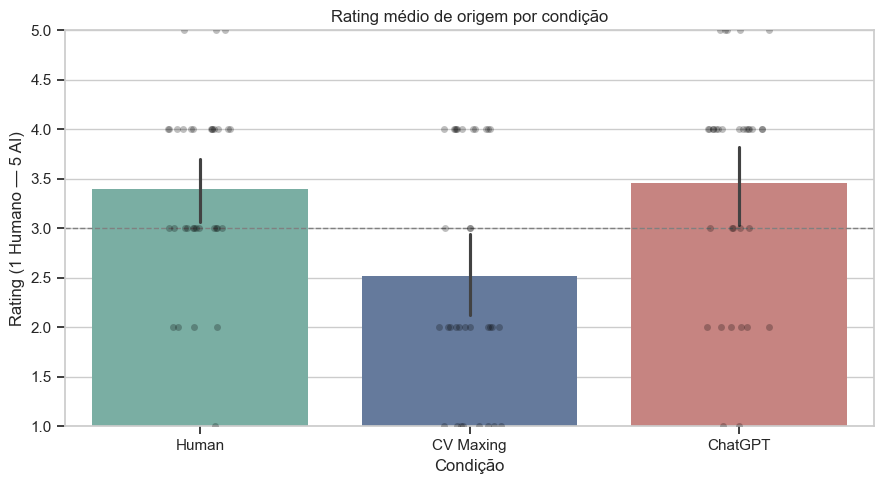

Classificação Likely/Definitely AI (rating >= 4):
Human: 16/33 (48.5%); p vs 50%=0.6358
CV Maxing: 11/33 (33.3%); p vs 50%=0.9825
ChatGPT: 20/33 (60.6%); p vs 50%=0.1481


In [3]:
condition_perception = (long.groupby("condition")
                        .agg(mean_rating=("ai_rating", "mean"),
                             median_rating=("ai_rating", "median"),
                             sd=("ai_rating", "std"),
                             n=("ai_rating", "count"))
                        .reindex(["Human", "CV Maxing", "ChatGPT"]))
display(condition_perception.round(2))

order = ["Human", "CV Maxing", "ChatGPT"]
colors = ["#72B6A8", "#5C78A5", "#D27A75"]
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=long, x="condition", y="ai_rating", order=order,
                 estimator=np.mean, errorbar=("ci", 95), palette=colors)
sns.stripplot(data=long, x="condition", y="ai_rating", order=order,
              color="black", alpha=.25, jitter=.12, ax=ax)
ax.axhline(3, color="grey", linestyle="--", linewidth=1)
ax.set_title("Rating médio de origem por condição")
ax.set_xlabel("Condição")
ax.set_ylabel("Rating (1 Humano — 5 AI)")
ax.set_ylim(1, 5)
plt.tight_layout()
plt.show()

print("Classificação Likely/Definitely AI (rating >= 4):")
for cond in order:
    sub = long.loc[long["condition"] == cond, "ai_rating"].dropna()
    k = int((sub >= 4).sum())
    n = len(sub)
    p = binomtest(k, n, 0.5, alternative="greater").pvalue
    print(f"{cond}: {k}/{n} ({k/n:.1%}); p vs 50%={p:.4f}")

## 3. Teste de Turing — detecção da versão humana

Uma distribuição uniforme por três versões produziria cerca de 33% por condição. Os votos são apresentados por caso e agregados.

selected_human,Human,CV Maxing,ChatGPT
case_name,,,
Caso 1 — Tomás,1,7,3
Caso 2 — Pedro,1,7,3
Caso 3 — Rita,5,3,3


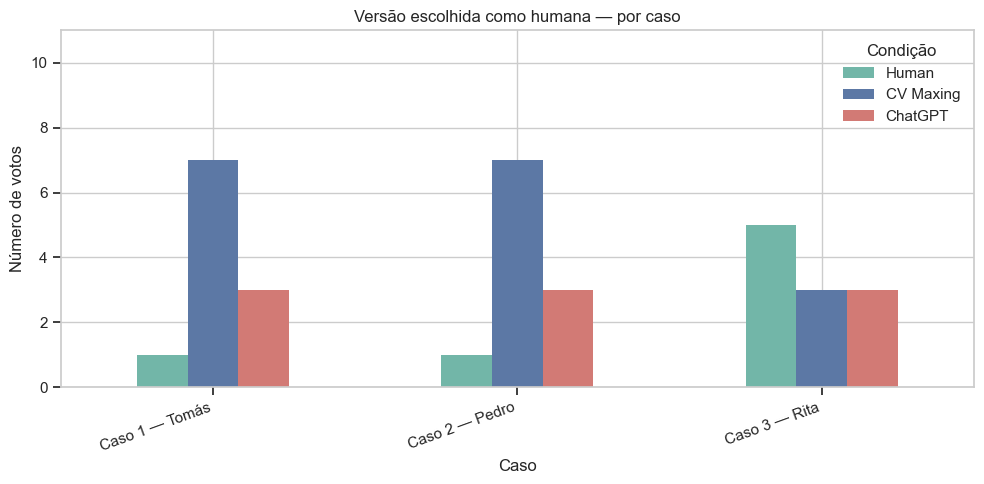

Totais agregados:
selected_human
Human         7
CV Maxing    17
ChatGPT       9
Name: count, dtype: int64

Taxas:
selected_human
Human        0.212
CV Maxing    0.515
ChatGPT      0.273
Name: count, dtype: float64

Testes binomiais por caso contra 1/3:
Caso 1 — Tomás
  Human: 1/11 (9.1%), p > 1/3 = 0.9884
  CV Maxing: 7/11 (63.6%), p > 1/3 = 0.0386
  ChatGPT: 3/11 (27.3%), p > 1/3 = 0.7659
Caso 2 — Pedro
  Human: 1/11 (9.1%), p > 1/3 = 0.9884
  CV Maxing: 7/11 (63.6%), p > 1/3 = 0.0386
  ChatGPT: 3/11 (27.3%), p > 1/3 = 0.7659
Caso 3 — Rita
  Human: 5/11 (45.5%), p > 1/3 = 0.2890
  CV Maxing: 3/11 (27.3%), p > 1/3 = 0.7659
  ChatGPT: 3/11 (27.3%), p > 1/3 = 0.7659


In [4]:
responses = long.drop_duplicates(["respondent", "case"])
human_votes = (responses.groupby(["case_name", "selected_human"])
               .size().unstack(fill_value=0)
               .reindex(columns=order, fill_value=0))
display(human_votes)

human_votes.plot(kind="bar", figsize=(10, 5), color=colors)
plt.title("Versão escolhida como humana — por caso")
plt.xlabel("Caso")
plt.ylabel("Número de votos")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, valid_n)
plt.legend(title="Condição")
plt.tight_layout()
plt.show()

human_totals = responses["selected_human"].value_counts().reindex(order, fill_value=0)
print("Totais agregados:")
print(human_totals)
print("\nTaxas:")
print((human_totals / human_totals.sum()).round(3))

print("\nTestes binomiais por caso contra 1/3:")
for case, name in case_names.items():
    subset = responses[responses["case"] == case]
    votes = subset["selected_human"].value_counts()
    n = len(subset)
    print(name)
    for cond in order:
        k = int(votes.get(cond, 0))
        p = binomtest(k, n, 1/3, alternative="greater").pvalue
        print(f"  {cond}: {k}/{n} ({k/n:.1%}), p > 1/3 = {p:.4f}")

## 4. Recomendação de entrevista

Para cada caso, os participantes escolheram a versão que recomendariam ao hiring manager.

selected_interview,Human,CV Maxing,ChatGPT
case_name,,,
Caso 1 — Tomás,3,2,6
Caso 2 — Pedro,4,3,4
Caso 3 — Rita,6,3,2


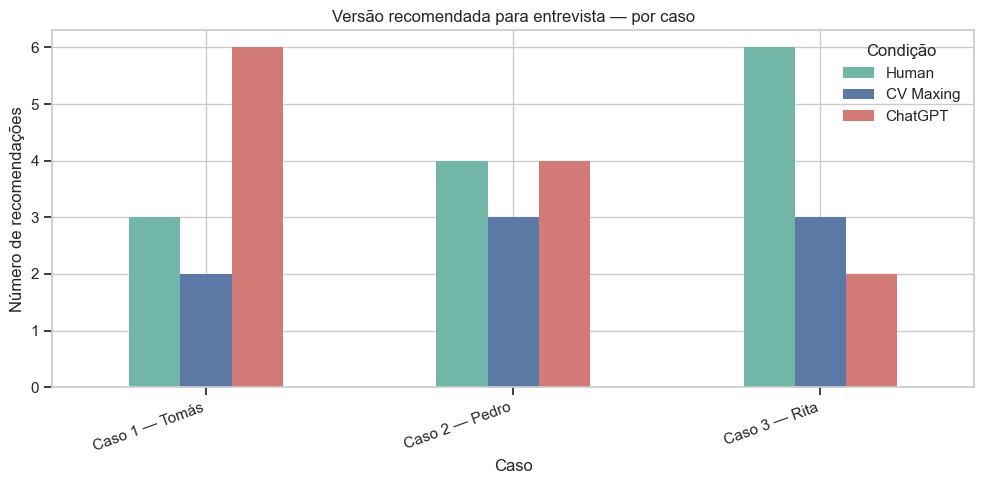

Totais agregados:
selected_interview
Human        13
CV Maxing     8
ChatGPT      12
Name: count, dtype: int64

Percentagens:
selected_interview
Human        0.394
CV Maxing    0.242
ChatGPT      0.364
Name: count, dtype: float64


In [5]:
interview_table = (responses.groupby(["case_name", "selected_interview"])
                   .size().unstack(fill_value=0)
                   .reindex(columns=order, fill_value=0))
display(interview_table)

interview_table.plot(kind="bar", figsize=(10, 5), color=colors)
plt.title("Versão recomendada para entrevista — por caso")
plt.xlabel("Caso")
plt.ylabel("Número de recomendações")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Condição")
plt.tight_layout()
plt.show()

interview_totals = responses["selected_interview"].value_counts().reindex(order, fill_value=0)
print("Totais agregados:")
print(interview_totals)
print("\nPercentagens:")
print((interview_totals / interview_totals.sum()).round(3))

## 5. Correlação entre rating e decisões

Cada observação representa participante × caso × condição. **Spearman rho** mede associação monotónica; **point-biserial r** mede associação linear com uma escolha binária.

São análises exploratórias, dado o tamanho da amostra e a repetição por participante.

Rating AI vs escolhido como humano:
Spearman rho=-0.711, p=0.0000
Point-biserial r=-0.735, p=0.0000

Rating AI vs recomendado para entrevista:
Spearman rho=-0.301, p=0.0025
Point-biserial r=-0.276, p=0.0057


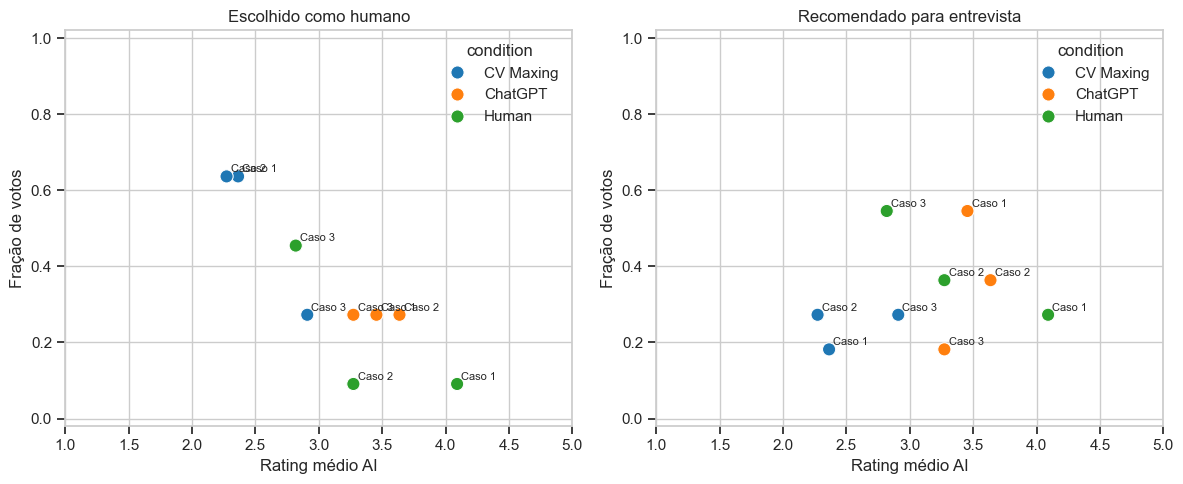

Agregado caso-condição: rating/seleção humana rho=-0.820, p=0.0068
Agregado caso-condição: rating/entrevista rho=0.259, p=0.5015


In [6]:
corr = long.dropna(subset=["ai_rating", "selected_human_match", "selected_interview_match"])

rho, p = spearmanr(corr["ai_rating"], corr["selected_human_match"])
r_pb, p_pb = pointbiserialr(corr["selected_human_match"], corr["ai_rating"])
print("Rating AI vs escolhido como humano:")
print(f"Spearman rho={rho:.3f}, p={p:.4f}")
print(f"Point-biserial r={r_pb:.3f}, p={p_pb:.4f}")

rho, p = spearmanr(corr["ai_rating"], corr["selected_interview_match"])
r_pb, p_pb = pointbiserialr(corr["selected_interview_match"], corr["ai_rating"])
print("\nRating AI vs recomendado para entrevista:")
print(f"Spearman rho={rho:.3f}, p={p:.4f}")
print(f"Point-biserial r={r_pb:.3f}, p={p_pb:.4f}")

agg = corr.groupby(["case_name", "condition"]).agg(
    mean_ai_rating=("ai_rating", "mean"),
    human_share=("selected_human_match", "mean"),
    interview_share=("selected_interview_match", "mean"),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, y, title in [(axes[0], "human_share", "Escolhido como humano"),
                     (axes[1], "interview_share", "Recomendado para entrevista")]:
    sns.scatterplot(data=agg, x="mean_ai_rating", y=y, hue="condition", s=90, ax=ax)
    for _, row in agg.iterrows():
        ax.annotate(row["case_name"].split(" — ")[0],
                    (row["mean_ai_rating"], row[y]), xytext=(3, 3),
                    textcoords="offset points", fontsize=8)
    ax.set_xlabel("Rating médio AI")
    ax.set_ylabel("Fração de votos")
    ax.set_title(title)
    ax.set_xlim(1, 5)
    ax.set_ylim(-0.02, 1.02)
plt.tight_layout()
plt.show()

rho_h, p_h = spearmanr(agg["mean_ai_rating"], agg["human_share"])
rho_i, p_i = spearmanr(agg["mean_ai_rating"], agg["interview_share"])
print(f"Agregado caso-condição: rating/seleção humana rho={rho_h:.3f}, p={p_h:.4f}")
print(f"Agregado caso-condição: rating/entrevista rho={rho_i:.3f}, p={p_i:.4f}")

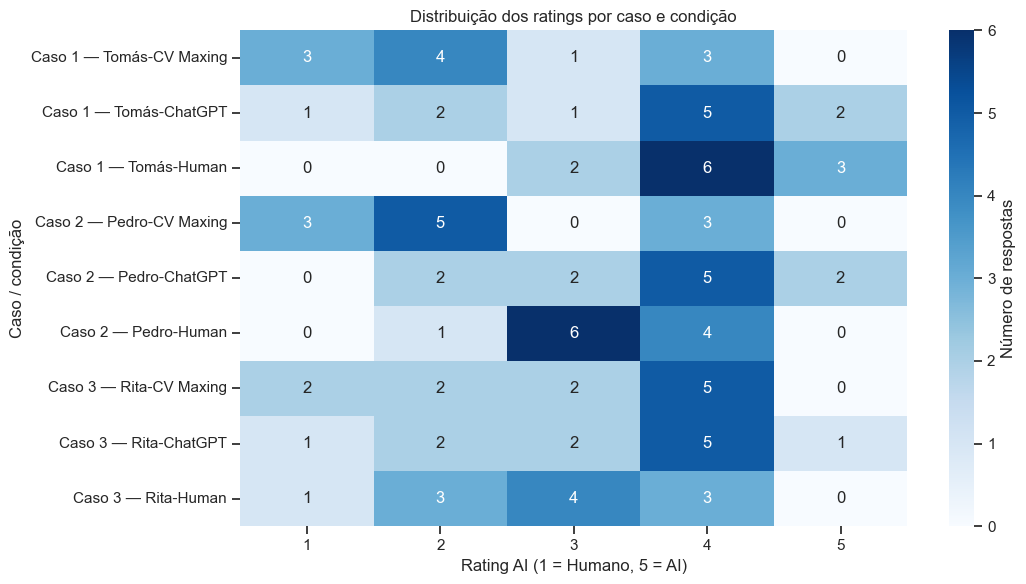

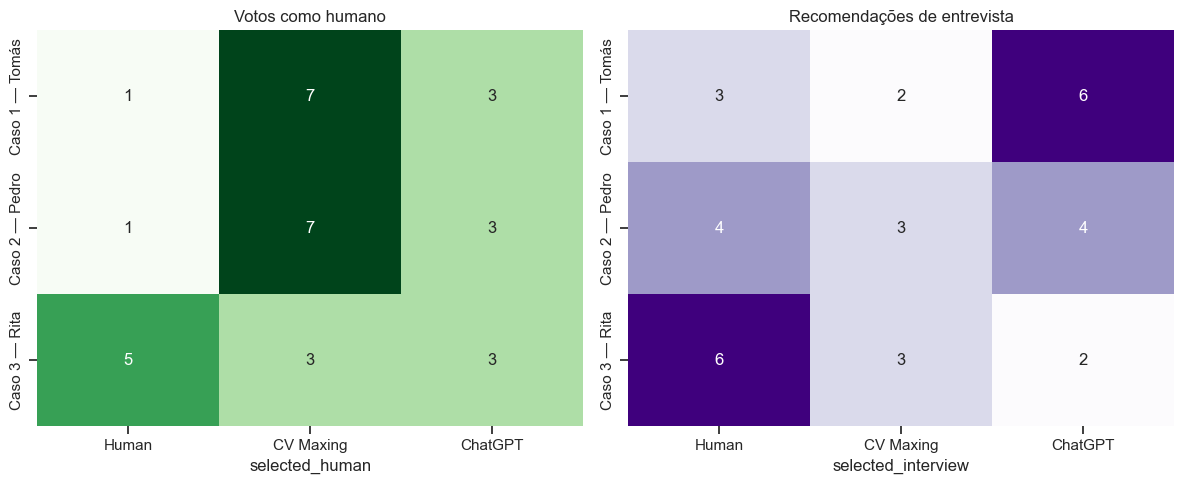

In [7]:
rating_grid = pd.crosstab([corr["case_name"], corr["condition"]], corr["ai_rating"])
plt.figure(figsize=(11, 6))
sns.heatmap(rating_grid, annot=True, fmt="d", cmap="Blues",
            cbar_kws={"label": "Número de respostas"})
plt.title("Distribuição dos ratings por caso e condição")
plt.xlabel("Rating AI (1 = Humano, 5 = AI)")
plt.ylabel("Caso / condição")
plt.tight_layout()
plt.show()

human_matrix = pd.crosstab(responses["case_name"], responses["selected_human"])
interview_matrix = pd.crosstab(responses["case_name"], responses["selected_interview"])
human_matrix = human_matrix.reindex(columns=order, fill_value=0)
interview_matrix = interview_matrix.reindex(columns=order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(human_matrix, annot=True, fmt="d", cmap="Greens", ax=axes[0], cbar=False)
axes[0].set_title("Votos como humano")
axes[0].set_ylabel("")
sns.heatmap(interview_matrix, annot=True, fmt="d", cmap="Purples", ax=axes[1], cbar=False)
axes[1].set_title("Recomendações de entrevista")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## 6. Síntese das hipóteses

- **H1 — Baseline rejeitado:** espera-se que ChatGPT tenha >=70% dos ratings em 4–5.
- **H2 — CV Maxing indistinguível:** CV Maxing deve dividir a detecção humana de forma próxima ao Humano.
- **H3 — Confiança para entrevista:** CV Maxing deve igualar ou superar o Humano em recomendações.

In [8]:
chat_ratings = long.loc[long["condition"] == "ChatGPT", "ai_rating"].dropna()
h1_prop = (chat_ratings >= 4).mean()

human_control_votes = int(human_totals["Human"])
cv_votes = int(human_totals["CV Maxing"])
chat_votes = int(human_totals["ChatGPT"])
cv_interview = float(interview_totals["CV Maxing"] / interview_totals.sum())
human_interview = float(interview_totals["Human"] / interview_totals.sum())

synthesis = pd.DataFrame([
    ["H1 — Baseline rejeitado",
     f"{h1_prop:.1%} dos ratings de ChatGPT são >= 4",
     "Suportada" if h1_prop > 0.70 else "Não suportada"],
    ["H2 — CV Maxing indistinguível",
     f"Votos humanos: Human={human_control_votes}, CV Maxing={cv_votes}, ChatGPT={chat_votes}",
     "Indicadores próximos" if abs(human_control_votes - cv_votes) <= 5 else "Divergência visível"],
    ["H3 — Confiança para entrevista",
     f"CV Maxing={cv_interview:.1%}; Human={human_interview:.1%}",
     "Suportada" if cv_interview >= human_interview else "Não suportada"],
], columns=["Hipótese", "Resultado observado", "Avaliação piloto"])
display(synthesis)

print("Nota: amostra n=11 participantes; intervalos e p-valores são piloto.")

,Hipótese,Resultado observado,Avaliação piloto
0,H1 — Baseline rejeitado,60.6% dos ratings de ChatGPT são >= 4,Não suportada
1,H2 — CV Maxing indistinguível,"Votos humanos: Human=7, CV Maxing=17, ChatGPT=9",Divergência visível
2,H3 — Confiança para entrevista,CV Maxing=24.2%; Human=39.4%,Não suportada


Nota: amostra n=11 participantes; intervalos e p-valores são piloto.


## 7. Interpretação e limitações

- A amostra atual é pequena (`n=11`) e não permite inferência robusta sobre recrutadores ou sobre a população geral;
- não foram recolhidas experiência profissional, função ou dimensão organizacional;
- os comentários opcionais não têm conteúdo neste ficheiro, pelo que não é possível codificar justificações qualitativas;
- a detecção humana é uma escolha forçada entre três opções, não uma medida directa de factualidade;
- recomendações de entrevista podem refletir preferências pessoais além da qualidade objetiva;
- devem ser reportados intervalos de confiança e ampliada a amostra antes de publicar conclusões definitivas.

### Próxima fase

1. recolher mais respostas por caso;
2. manter o contrabalanço e pré-registar os critérios de sucesso;
3. codificar justificações abertas;
4. analisar separadamente recrutadores, engenheiros e participantes sem experiência profissional.